# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module – Research Assignment**

This notebook implements **recursive spectral modularity bisection** from scratch (NumPy + NetworkX only) on Zachary's Karate Club network, following Newman (2006), *"Modularity and community structure in networks"*, PNAS 103(23):8577–8582.

**Pipeline**
1. Build the modularity matrix $B = A - \frac{kk^\top}{2m}$.
2. Split a group by the sign of the leading eigenvector of its (restricted) modularity matrix.
3. Recurse until no group can be split. Record the partition after every split.
4. Visualise each partition with a fixed layout.
5. After each split, compute degree / betweenness / closeness centrality and clustering, and plot their evolution.
6. Discuss.

The notebook runs top-to-bottom with no manual edits and writes its figures to `assets/`.

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib import colormaps

os.makedirs("assets", exist_ok=True)
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("networkx", nx.__version__, "| numpy", np.__version__)

networkx 3.7 | numpy 2.5.4


## 1. Data and the modularity matrix

`nx.karate_club_graph()` stores edge *weights* in NetworkX ≥ 3.0. The assignment defines an **unweighted** adjacency matrix $A\in\{0,1\}^{n\times n}$, so we explicitly pass `weight=None`.

In [2]:
G = nx.karate_club_graph()                      # 34 nodes, 78 edges; nodes are 0..33
nodes = sorted(G.nodes())
n, m = G.number_of_nodes(), G.number_of_edges()

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted 0/1 adjacency
k = A.sum(axis=1)                                       # degree vector
B = A - np.outer(k, k) / (2 * m)                        # modularity matrix

# Ground truth: the real split of the club (Mr. Hi vs. Officer)
truth = {v: G.nodes[v]["club"] for v in G}

# --- sanity checks tied to the handout's propositions ---
assert (n, m) == (34, 78)
assert np.allclose(A, A.T) and set(np.unique(A)) <= {0.0, 1.0}
assert np.allclose(B, B.T),            "Proposition 1: B is symmetric"
assert np.allclose(B @ np.ones(n), 0), "Proposition 2: B 1 = 0"
print(f"n = {n}, m = {m}, sum of degrees = {int(k.sum())} (= 2m = {2*m})")
print("Largest eigenvalue of B:", np.linalg.eigvalsh(B)[-1].round(4),
      "| smallest |eig| (should be ~0 from B1=0):", np.abs(np.linalg.eigvalsh(B)).min().round(10))

n = 34, m = 78, sum of degrees = 156 (= 2m = 156)
Largest eigenvalue of B: 4.9771 | smallest |eig| (should be ~0 from B1=0): 0.0


## 2. Modularity of an arbitrary partition

For a partition into communities $C_1,\dots,C_r$ the modularity is
$$Q=\frac{1}{2m}\sum_{c}\sum_{i,j\in C_c} B_{ij},$$
which equals $\frac{1}{4m}s^\top B s$ in the two-community case. We validate our implementation against `networkx.community.modularity`.

In [3]:
def modularity(partition, B=B, m=m):
    # partition: list of lists of node ids.  Q = (1/2m) * sum over communities of the block sum of B.
    return sum(B[np.ix_(c, c)].sum() for c in partition) / (2 * m)

# Check 1: trivial partition has Q = 0 (Corollary 1)
print("Q(trivial)         =", round(modularity([nodes]), 12))

# Check 2: agree with networkx on the true split
true_part = [[v for v in nodes if truth[v] == "Mr. Hi"], [v for v in nodes if truth[v] == "Officer"]]
q_mine = modularity(true_part)
q_nx = nx.community.modularity(G, [set(c) for c in true_part], weight=None)
print(f"Q(true split) mine = {q_mine:.6f} | networkx = {q_nx:.6f}")
assert np.isclose(q_mine, q_nx)

Q(trivial)         = -0.0
Q(true split) mine = 0.358235 | networkx = 0.358235


## 3. Spectral bisection and recursive splitting

**Split step** for a group $C$: build the restricted matrix, take its leading eigenpair $(\lambda_1^{(C)},u_1^{(C)})$ (`numpy.linalg.eigh`, appropriate because the matrix is real symmetric), stop if $\lambda_1^{(C)}\le 0$, otherwise assign $+1$ to entries $>0$ and $-1$ otherwise.

**Two variants of the restricted matrix** (selected via `variant=`):

| `variant` | Restricted matrix | Notes |
|---|---|---|
| `"handout"` *(main results)* | $B^{(C)}_{ij}=A_{ij}-\frac{k_ik_j}{2m},\ i,j\in C$ — the plain block of $B$, exactly as specified in the handout | The assignment's method. |
| `"newman"` *(comparison, §8)* | $B^{(C)}_{ij}-\delta_{ij}\sum_{l\in C}B^{(C)}_{il}$ and requiring an actual gain $\Delta Q>0$ | Newman's generalised matrix (2006, Eq. 6). The diagonal correction makes the row sums zero, so $\Delta Q=\frac1{4m}s^\top B^{(C)}s$ is *exactly* the change in global modularity — which the plain block does **not** guarantee, since its rows do not sum to zero. |

I use the handout variant for all required deliverables and the Newman variant only as a cross-check (§8).

In [4]:
def restricted_matrix(B, group, variant="handout"):
    # Restricted modularity matrix B^(C) for the node set `group`.
    idx = np.asarray(sorted(group))
    Bc = B[np.ix_(idx, idx)].copy()
    if variant == "newman":
        Bc -= np.diag(Bc.sum(axis=1))      # subtract row sums on the diagonal -> rows sum to 0
    return idx, Bc

def leading_eigenpair(M):
    # Leading (largest) eigenvalue and unit eigenvector of a real symmetric matrix.
    w, V = np.linalg.eigh(M)               # eigenvalues in ascending order
    lam, u = w[-1], V[:, -1].copy()
    # eigenvectors are only defined up to sign: fix it so the first non-zero entry is positive
    first = u[np.argmax(np.abs(u) > 1e-12)]
    return lam, (u if first >= 0 else -u)

def try_split(B, group, variant="handout", tol=1e-9):
    # Attempt to split `group`. Returns (C_plus, C_minus, lambda1); the parts are None if indivisible.
    idx, Bc = restricted_matrix(B, group, variant)
    if len(idx) < 2:
        return None, None, float("nan")
    lam, u = leading_eigenpair(Bc)
    if lam <= tol:                          # Theorem 3 stopping rule: no positive eigenvalue
        return None, None, lam
    s = np.where(u > 0, 1, -1)              # threshold back to {-1, +1}
    if abs(s.sum()) == len(s):              # every node on the same side -> not a real split
        return None, None, lam
    if variant == "newman" and (s @ Bc @ s) / (4 * m) <= tol:   # discrete split must truly gain modularity
        return None, None, lam
    return [int(i) for i in idx[s == 1]], [int(i) for i in idx[s == -1]], lam

### Recursive bisection driver

A queue processes groups first-in-first-out. **One iteration = one accepted split.** Iteration 0 is the whole graph as a single community ($Q=0$). Each community keeps a stable integer id; on a split the `+` part inherits the parent's id and the `−` part gets a new id, so colours stay comparable across iterations.

In [5]:
def recursive_bisection(B, variant="handout", verbose=True):
    # Returns (history, tests). history[t] describes the partition after t splits.
    from collections import deque
    comm = {0: list(nodes)}                 # id -> nodes
    next_id = 1
    history = [dict(iteration=0, comm={c: list(v) for c, v in comm.items()},
                    Q=modularity(list(comm.values())), split=None)]
    tests = []                              # every eigenvalue test performed (accepted or not)
    queue = deque([0])
    while queue:
        cid = queue.popleft()
        plus, minus, lam = try_split(B, comm[cid], variant)
        tests.append(dict(community=cid, size=len(comm[cid]), lambda1=lam, split=plus is not None))
        if plus is None:
            continue
        new = next_id; next_id += 1
        comm[cid], comm[new] = plus, minus
        queue.extend([cid, new])
        Q = modularity(list(comm.values()))
        history.append(dict(iteration=len(history), comm={c: sorted(v) for c, v in comm.items()},
                            Q=Q, split=(cid, new, lam)))
        if verbose:
            print(f"iter {len(history)-1}: split community {cid} (|C|={len(plus)+len(minus)}, "
                  f"lambda1={lam:.3f}) -> sizes {len(plus)} + {len(minus)} | Q = {Q:.4f}")
    return history, pd.DataFrame(tests)

history, tests = recursive_bisection(B, variant="handout")
print(f"\nFinal: {len(history[-1]['comm'])} communities, Q = {history[-1]['Q']:.4f}")
tests

iter 1: split community 0 (|C|=34, lambda1=4.977) -> sizes 16 + 18 | Q = 0.3715
iter 2: split community 0 (|C|=16, lambda1=2.944) -> sizes 10 + 6 | Q = 0.3898
iter 3: split community 1 (|C|=18, lambda1=2.504) -> sizes 13 + 5 | Q = 0.4081
iter 4: split community 2 (|C|=6, lambda1=2.148) -> sizes 5 + 1 | Q = 0.4094

Final: 5 communities, Q = 0.4094


,community,size,lambda1,split
0,0,34,4.977,True
1,0,16,2.944,True
2,1,18,2.504,True
3,0,10,2.571,False
4,2,6,2.148,True
5,1,13,2.356,False
6,3,5,1.876,False
7,2,5,2.147,False
8,4,1,NaN,False


In [6]:
# Final communities
for cid, members in sorted(history[-1]["comm"].items()):
    print(f"community {cid} (size {len(members)}): {sorted(members)}")

# Cross-check final modularity against NetworkX
final_sets = [set(v) for v in history[-1]["comm"].values()]
print("\nQ (mine)     =", round(history[-1]["Q"], 6))
print("Q (networkx) =", round(nx.community.modularity(G, final_sets, weight=None), 6))

community 0 (size 10): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
community 1 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
community 2 (size 5): [4, 5, 6, 10, 16]
community 3 (size 5): [24, 25, 27, 28, 31]
community 4 (size 1): [11]

Q (mine)     = 0.409435
Q (networkx) = 0.409435


## 4. Does the first split recover the real club split?

Zachary recorded the actual fission (`club` attribute: *Mr. Hi* vs. *Officer*). After the first split only two communities exist, so we can compare directly.

In [7]:
first = history[1]["comm"]
groupA, groupB = sorted(first[0]), sorted(first[1])
hi = {v for v in nodes if truth[v] == "Mr. Hi"}

# the two spectral groups can be matched to the two real factions in two ways; take the better one
def mismatches(pred_hi):
    return sorted(set(pred_hi) ^ hi)
errA, errB = mismatches(groupA), mismatches(groupB)
mis = errA if len(errA) <= len(errB) else errB
print(f"Spectral groups: sizes {len(groupA)} and {len(groupB)}  (true factions: {len(hi)} and {n-len(hi)})")
print(f"Misclassified nodes: {mis}  -> accuracy = {(n-len(mis))/n:.1%}")
print(f"Q of spectral split = {history[1]['Q']:.4f} | Q of the true split = {modularity(true_part):.4f}")
for v in mis:
    print(f"  node {v}: true faction = {truth[v]!r}, degree {int(k[v])}, "
          f"neighbours in Mr. Hi's group = {sum(1 for u in G[v] if truth[u]=='Mr. Hi')}, "
          f"in Officer's group = {sum(1 for u in G[v] if truth[u]=='Officer')}")

Spectral groups: sizes 16 and 18  (true factions: 17 and 17)
Misclassified nodes: [8]  -> accuracy = 97.1%
Q of spectral split = 0.3715 | Q of the true split = 0.3582
  node 8: true faction = 'Mr. Hi', degree 5, neighbours in Mr. Hi's group = 2, in Officer's group = 3


## 5. Visualisation after each split

The layout is computed **once** (`spring_layout`, fixed seed) and reused so that only the colours change between iterations. Nodes are labelled by ID.

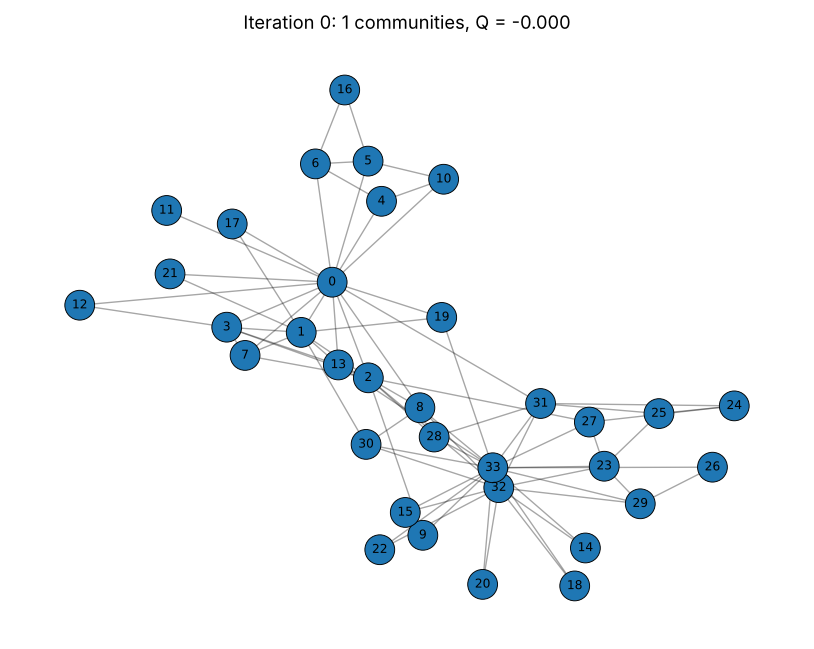

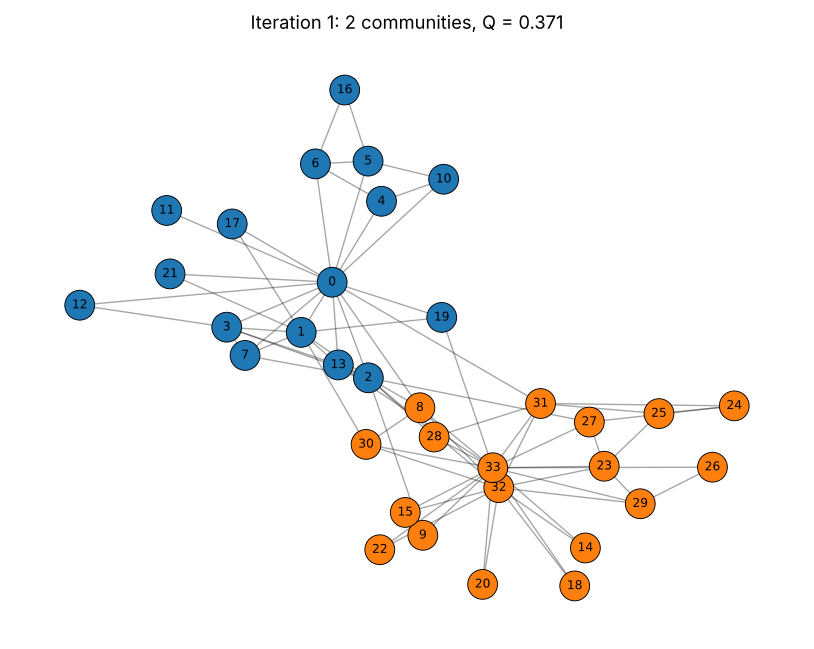

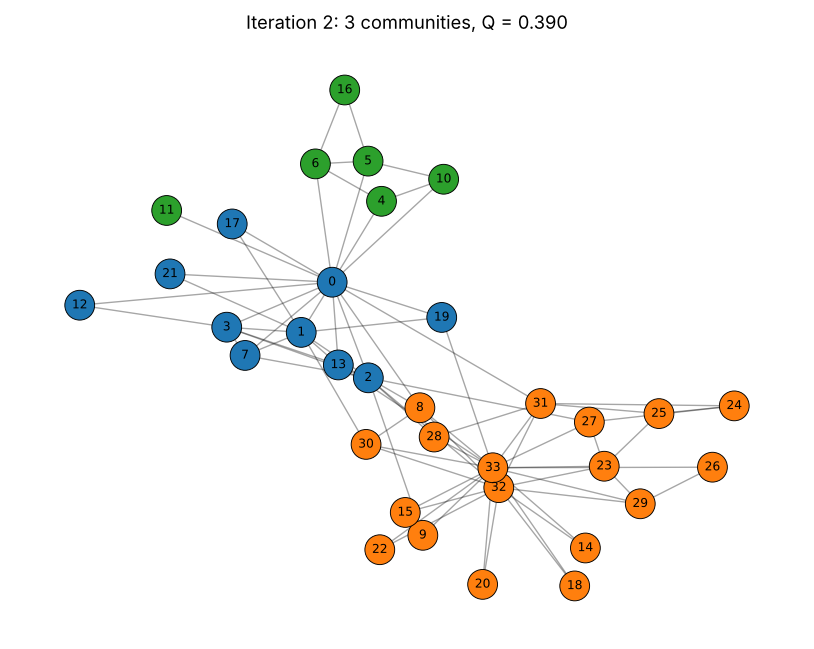

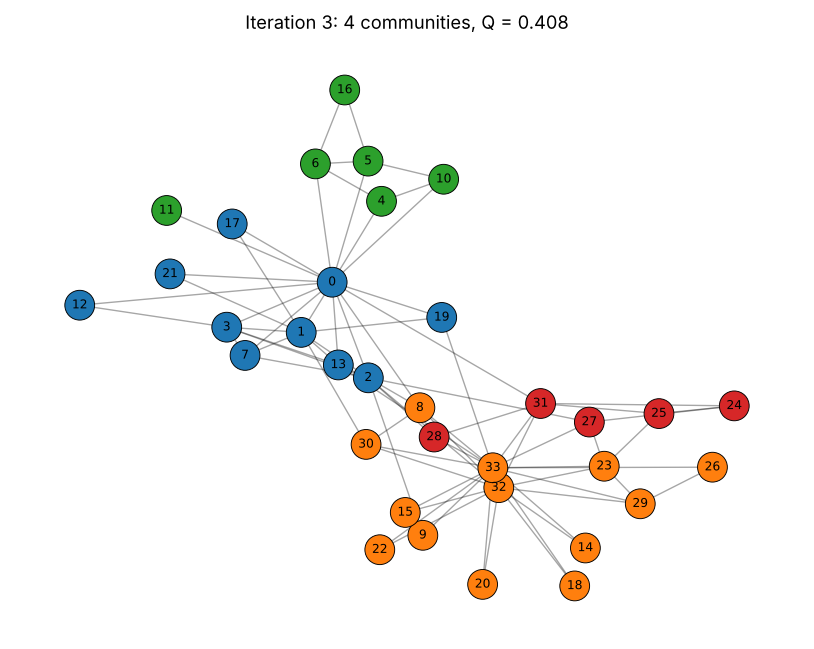

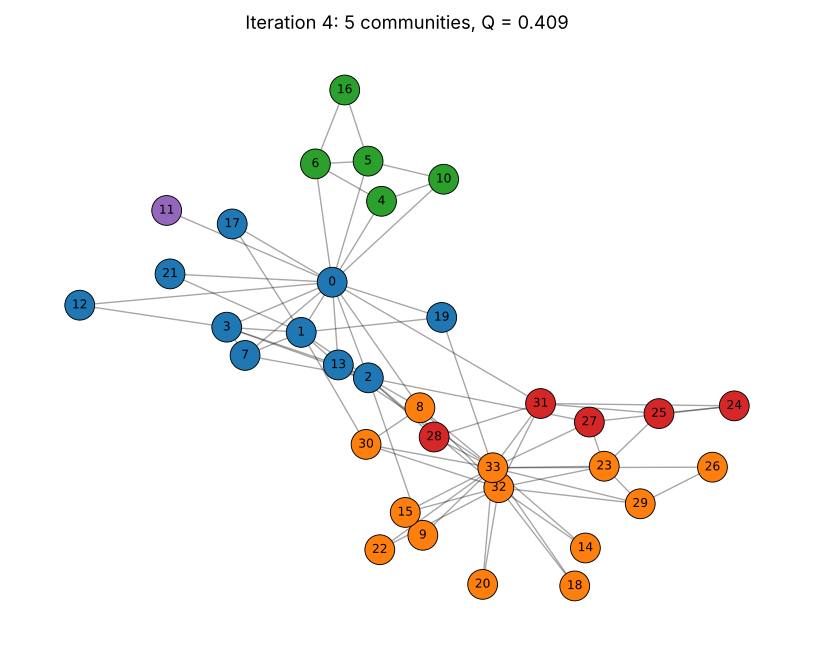

In [8]:
pos = nx.spring_layout(G, seed=42)                 # fixed layout for every figure
palette = colormaps["tab10"].colors

def draw_partition(h, ax=None, title=None):
    node_comm = {v: cid for cid, vs in h["comm"].items() for v in vs}
    colors = [palette[node_comm[v] % 10] for v in G.nodes()]
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7.5, 6))
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.9)
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=380, edgecolors="black", linewidths=0.6, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(title or f"Iteration {h['iteration']}: {len(h['comm'])} communities, Q = {h['Q']:.3f}")
    ax.axis("off")
    if own:
        plt.tight_layout()
        return fig

for h in history:
    fig = draw_partition(h)
    fig.savefig(f"assets/partition_iter{h['iteration']}.png", bbox_inches="tight")
    plt.show()

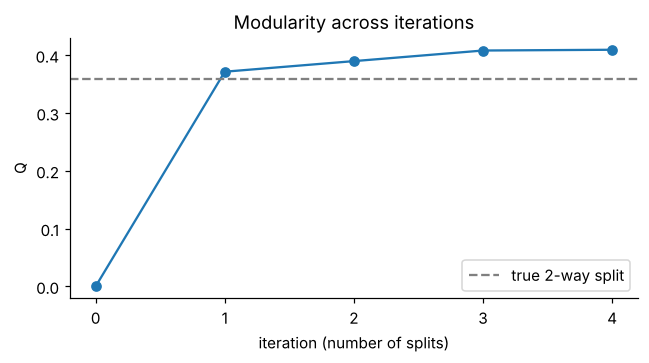

In [9]:
# Modularity as a function of the iteration
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot([h["iteration"] for h in history], [h["Q"] for h in history], "o-", color="tab:blue")
ax.axhline(modularity(true_part), ls="--", color="gray", label="true 2-way split")
ax.set_xlabel("iteration (number of splits)"); ax.set_ylabel("Q"); ax.set_xticks(range(len(history)))
ax.set_title("Modularity across iterations"); ax.legend()
plt.tight_layout(); fig.savefig("assets/modularity_vs_iteration.png"); plt.show()

## 6. Node metrics after each split

**How the metrics are defined across iterations.** Centrality computed on the *whole* graph does not depend on the partition, so it would be a flat line. To make the metrics reflect community structure, after each split I compute every metric on the **subgraph induced by each node's current community** (`G.subgraph(C)`), so each node is measured *relative to its own community*. Iteration 0 is therefore the ordinary whole-graph value. Conventions for degenerate cases: a singleton community gets 0 for every metric (NetworkX would return 1.0 for the degree centrality of a single node, which is not meaningful here); for a disconnected induced subgraph NetworkX's default closeness (Wasserman–Faust scaling) is used.

All four metrics use the NetworkX built-ins named in the handout.

In [10]:
METRICS = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def metrics_for_partition(G, comm):
    # {metric: {node: value}} where every metric is evaluated inside each node's own community.
    out = {name: {} for name in METRICS}
    for members in comm.values():
        H = G.subgraph(members)
        for name, fn in METRICS.items():
            vals = {v: 0.0 for v in members} if len(members) == 1 else fn(H)
            out[name].update(vals)
    return out

# metric_history[name] is a DataFrame: rows = nodes, columns = iteration number
by_iter = {h["iteration"]: metrics_for_partition(G, h["comm"]) for h in history}
metric_history = {name: pd.DataFrame({t: pd.Series(by_iter[t][name]) for t in by_iter}).sort_index()
                  for name in METRICS}

# Sanity check: iteration 0 must equal the plain whole-graph NetworkX values
for name, fn in METRICS.items():
    assert np.allclose(metric_history[name][0].sort_index().values, pd.Series(fn(G)).sort_index().values)
print("Iteration-0 values match NetworkX on the full graph.")
metric_history["Degree centrality"].head(8)

Iteration-0 values match NetworkX on the full graph.


,0,1,2,3,4
0,0.485,0.933,1.000,1.000,1.000
1,0.273,0.533,0.889,0.889,0.889
2,0.303,0.333,0.556,0.556,0.556
3,0.182,0.400,0.667,0.667,0.667
4,0.091,0.200,0.400,0.400,0.500
5,0.121,0.267,0.600,0.600,0.750
6,0.121,0.267,0.600,0.600,0.750
7,0.121,0.267,0.444,0.444,0.444


In [11]:
# Dictionary keyed by iteration number, as in the handout (iteration -> metric -> node -> value)
print({t: list(v.keys()) for t, v in list(by_iter.items())[:2]}, "...")

{0: ['Degree centrality', 'Betweenness centrality', 'Closeness centrality', 'Clustering coefficient'], 1: ['Degree centrality', 'Betweenness centrality', 'Closeness centrality', 'Clustering coefficient']} ...


### Evolution of each metric (line plots)

Each line is one node. The 5 nodes with the highest *average* value over all iterations are coloured and labelled; the rest are grey.

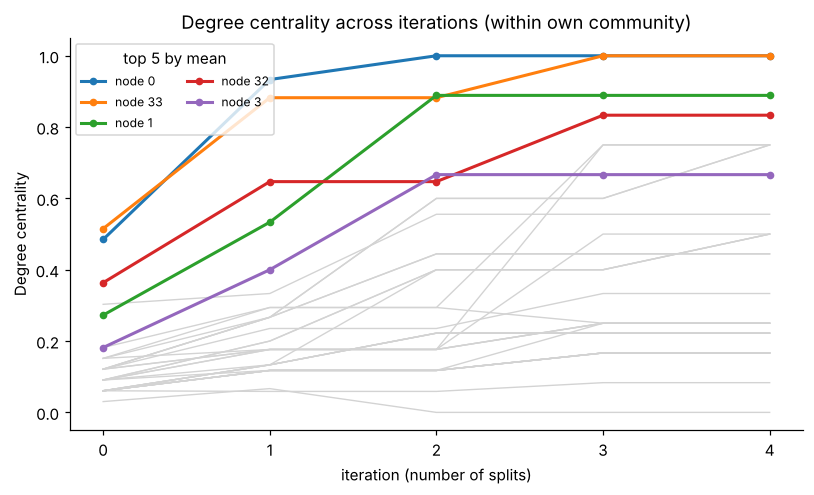

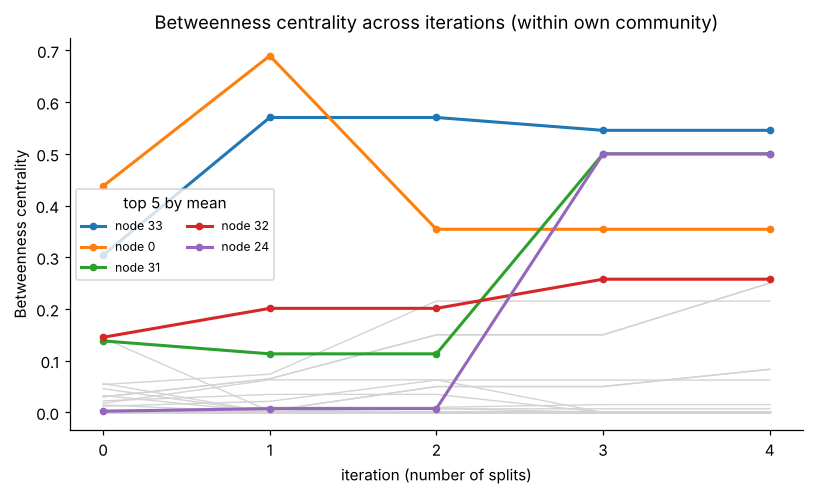

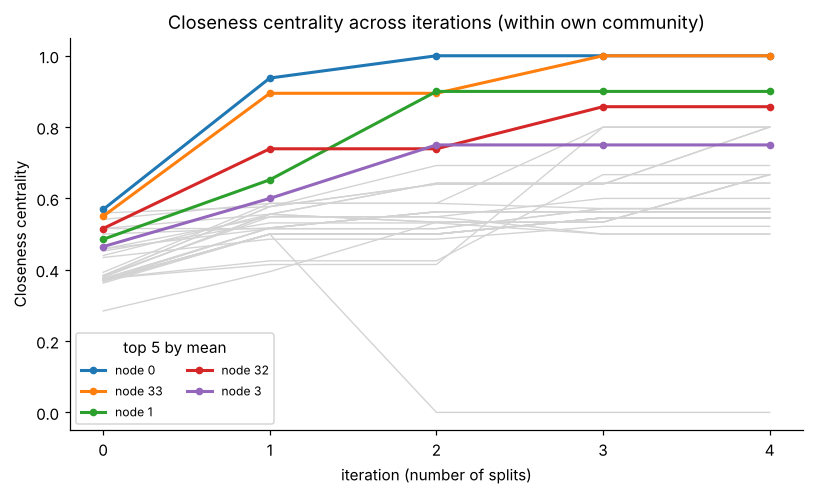

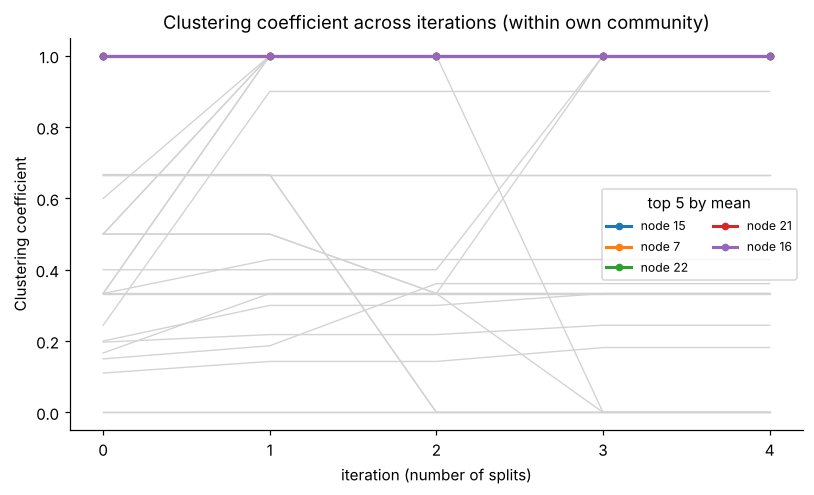

In [12]:
def plot_metric_lines(name, df, top=5):
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    leaders = df.mean(axis=1).sort_values(ascending=False).index[:top]
    for v in df.index:
        if v not in leaders:
            ax.plot(df.columns, df.loc[v], color="lightgray", lw=0.9, zorder=1)
    for i, v in enumerate(leaders):
        ax.plot(df.columns, df.loc[v], "o-", color=palette[i], lw=2, ms=4, label=f"node {v}", zorder=3)
    ax.set_xticks(list(df.columns)); ax.set_xlabel("iteration (number of splits)")
    ax.set_ylabel(name); ax.set_title(f"{name} across iterations (within own community)")
    ax.legend(title=f"top {top} by mean", fontsize=8, ncol=2, loc="best")
    plt.tight_layout()
    return fig

for name, df in metric_history.items():
    fig = plot_metric_lines(name, df)
    fig.savefig("assets/metric_lines_" + name.split()[0].lower() + ".png", bbox_inches="tight")
    plt.show()

### Evolution of each metric (heatmaps, all 34 nodes)

Rows are nodes sorted by their iteration-0 value, so every node can be read off, not just the leaders.

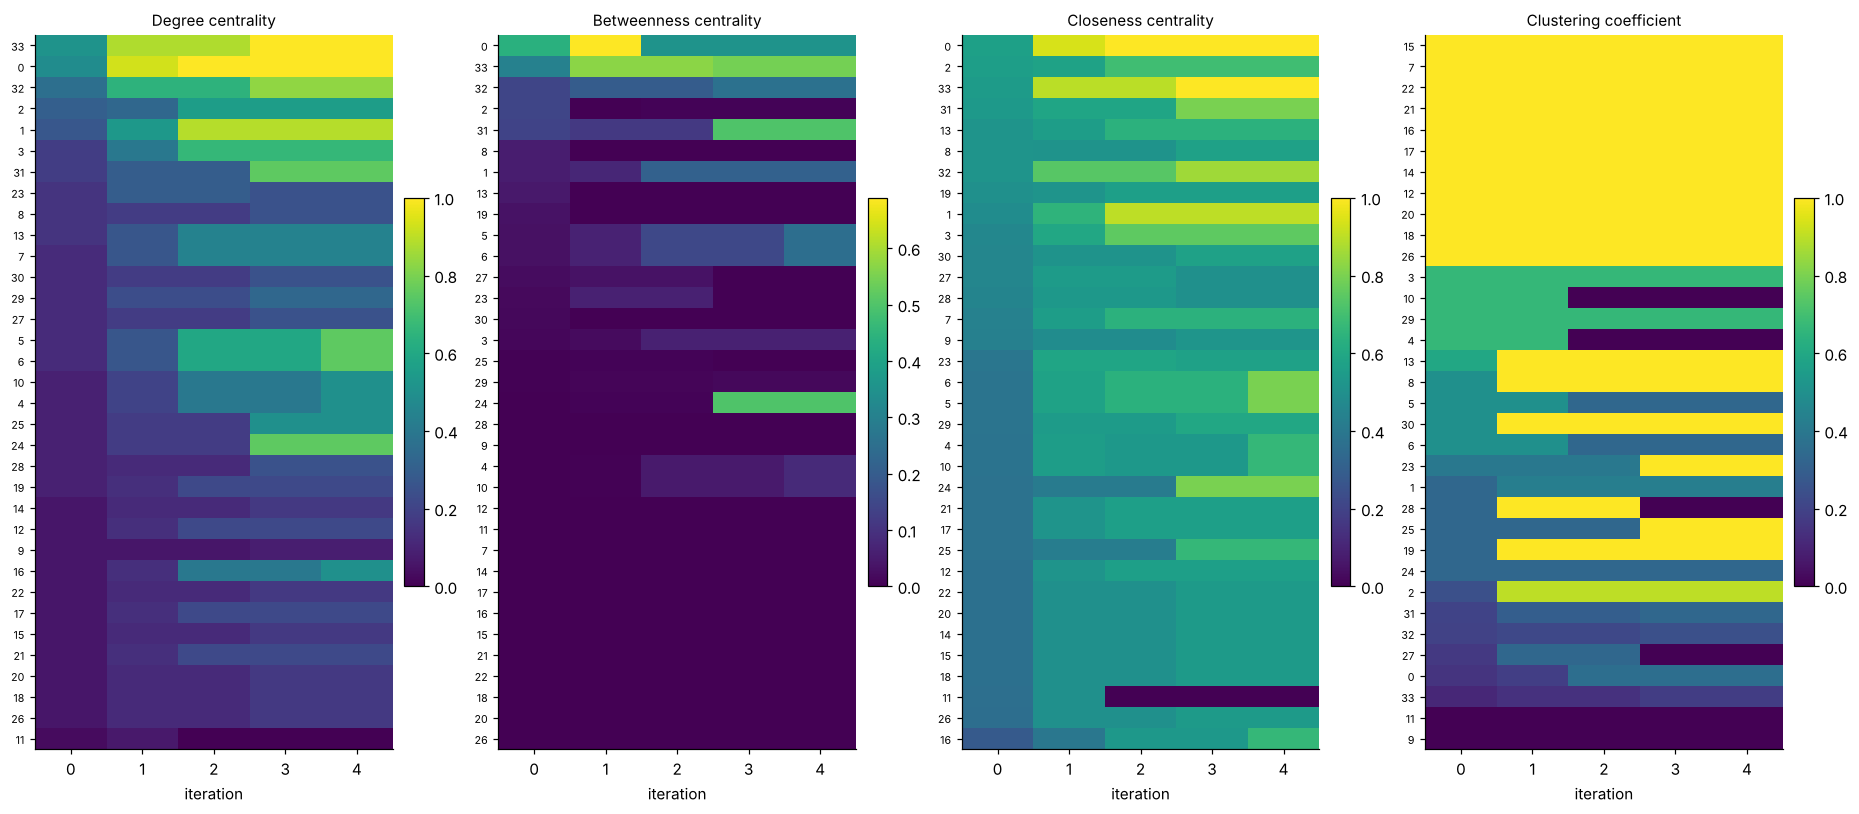

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(17, 7.5), sharey=False)
for ax, (name, df) in zip(axes, metric_history.items()):
    d = df.loc[df[0].sort_values(ascending=False).index]
    im = ax.imshow(d.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(d.shape[1])); ax.set_xticklabels(d.columns)
    ax.set_yticks(range(d.shape[0])); ax.set_yticklabels(d.index, fontsize=7)
    ax.set_xlabel("iteration"); ax.set_title(name, fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
plt.tight_layout(); fig.savefig("assets/metric_heatmaps.png", bbox_inches="tight"); plt.show()

## 7. Quantitative support for the discussion

In [14]:
final_t = history[-1]["iteration"]
node_comm_final = {v: cid for cid, vs in history[-1]["comm"].items() for v in vs}

# (a) Who is on top at every iteration?  Top-3 nodes per metric per iteration.
rows = []
for name, df in metric_history.items():
    for t in df.columns:
        top3 = df[t].sort_values(ascending=False).index[:3].tolist()
        rows.append(dict(metric=name, iteration=t, top3=top3))
top_table = pd.DataFrame(rows).pivot(index="iteration", columns="metric", values="top3")
display(top_table)

# (b) How often does each node appear in a metric's top-5 across iterations (consistency)?
counts = pd.DataFrame({name: pd.Series(
    [v for t in df.columns for v in df[t].sort_values(ascending=False).index[:5]]).value_counts()
    for name, df in metric_history.items()}).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
print("Number of iterations (out of %d) a node is in the top 5 of each metric:" % len(history))
display(counts.sort_values("total", ascending=False).head(8))

# (c) Whole-graph (iteration 0) vs. final within-community values for the leading nodes
lead = counts.sort_values("total", ascending=False).index[:6]
cmp = pd.concat({name: pd.DataFrame({"iter 0": df.loc[lead, 0], f"iter {final_t}": df.loc[lead, final_t]})
                 for name, df in metric_history.items()}, axis=1)
cmp.insert(0, "final community", [node_comm_final[v] for v in lead])
cmp.insert(1, "community size", [len(history[-1]["comm"][node_comm_final[v]]) for v in lead])
display(cmp)

metric,Betweenness centrality,Closeness centrality,Clustering coefficient,Degree centrality
iteration,,,,
0,"[0, 33, 32]","[0, 2, 33]","[15, 7, 22]","[33, 0, 32]"
1,"[0, 33, 32]","[0, 33, 32]","[7, 8, 26]","[0, 33, 32]"
2,"[33, 0, 1]","[0, 1, 33]","[7, 8, 26]","[0, 1, 33]"
3,"[33, 24, 31]","[0, 33, 1]","[7, 8, 30]","[0, 33, 1]"
4,"[33, 24, 31]","[0, 33, 1]","[7, 8, 30]","[0, 33, 1]"


Number of iterations (out of 5) a node is in the top 5 of each metric:


,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient,total
0,5,5,5,0,15
33,5,5,5,0,15
32,5,5,4,0,14
1,5,2,4,0,11
31,1,4,2,0,7
7,0,0,0,5,5
17,0,0,0,4,4
3,2,0,2,0,4


final community community size Degree centrality         \
                                             iter 0 iter 4   
0                0             10             0.485  1.000   
33               1             13             0.515  1.000   
32               1             13             0.364  0.833   
1                0             10             0.273  0.889   
31               3              5             0.182  0.750   
7                0             10             0.121  0.444   

   Betweenness centrality        Closeness centrality         \
                   iter 0 iter 4               iter 0 iter 4   
0                   0.438  0.354                0.569  1.000   
33                  0.304  0.545                0.550  1.000   
32                  0.145  0.258                0.516  0.857   
1                   0.054  0.215                0.485  0.900   
31                  0.138  0.500                0.541  0.800   
7                   0.000  0.000                0.440  0.643   

   Clustering coefficient         
                   iter 0 iter 4  
0                   0.150  0.361  
33                  0.110  0.182  
32                  0.197  0.244  
1                   0.333  0.429  
31                  0.200  0.333  
7                   1.000  1.000

In [15]:
# (d) Spearman rank correlation of each metric between iteration 0 and later iterations:
#     how much does community structure re-order the nodes?
rc = pd.DataFrame({name: [df[0].corr(df[t], method="spearman") for t in df.columns]
                   for name, df in metric_history.items()}, index=[f"iter {t}" for t in range(len(history))])
display(rc)

,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
iter 0,1.000,1.000,1.000,1.000
iter 1,0.927,0.716,0.736,0.815
iter 2,0.777,0.693,0.693,0.688
iter 3,0.839,0.616,0.614,0.669
iter 4,0.813,0.609,0.526,0.669


## 8. Cross-check with Newman's generalised restricted matrix

The handout's restricted matrix is the plain block of $B$. Its rows do not sum to zero, so $s^\top B^{(C)}s/4m$ is not exactly the modularity change, and the rule "stop when $\lambda_1\le0$" is then a heuristic rather than a guarantee (Newman's paper adds the diagonal correction for this reason). Here the main method is run side-by-side with the corrected version, and I compare final modularity directly.

iter 1: split community 0 (|C|=34, lambda1=4.977) -> sizes 16 + 18 | Q = 0.3715
iter 2: split community 0 (|C|=16, lambda1=1.179) -> sizes 7 + 9 | Q = 0.3727
iter 3: split community 1 (|C|=18, lambda1=0.859) -> sizes 12 + 6 | Q = 0.3934


,variant,# communities,final Q,NetworkX Q (check)
0,handout (plain block),5,0.409,0.409
1,Newman (generalised),4,0.393,0.393


Newman variant: Q non-decreasing along the history? True
Handout variant: Q along history = [-0.     0.371  0.39   0.408  0.409] | non-decreasing? True


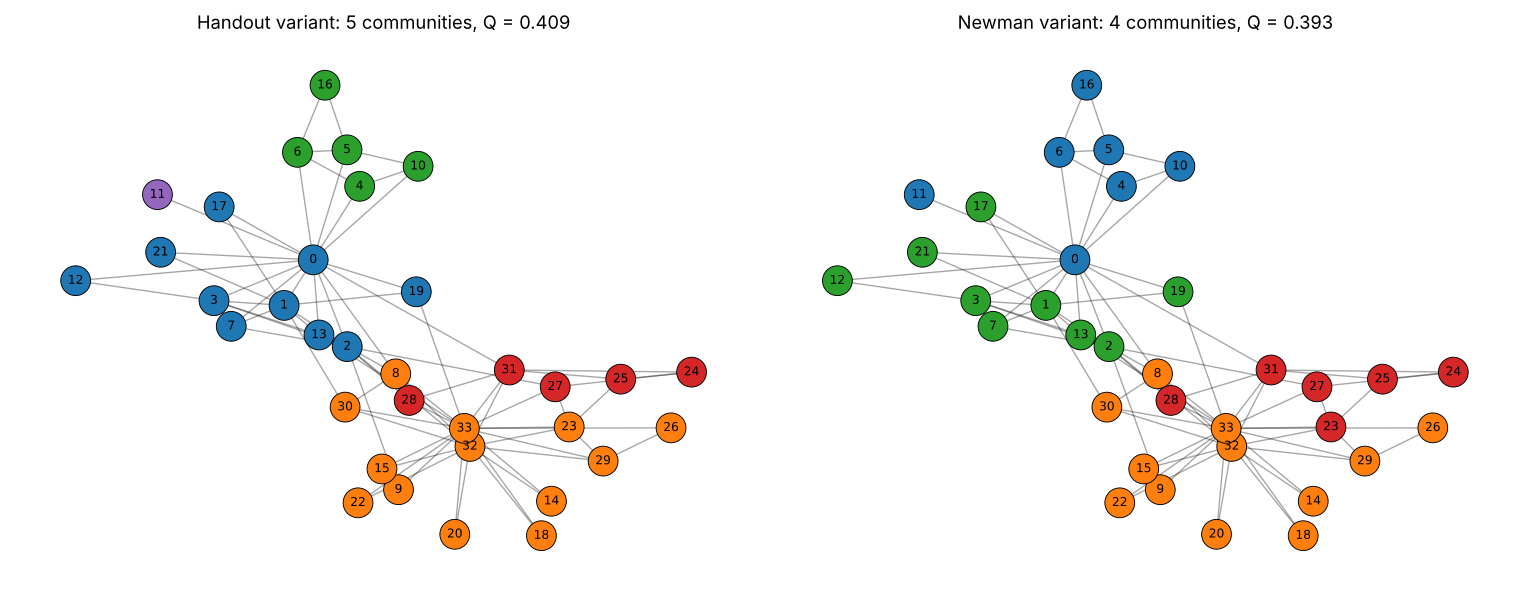

In [16]:
hist_newman, tests_newman = recursive_bisection(B, variant="newman", verbose=True)

summary = pd.DataFrame({
    "variant": ["handout (plain block)", "Newman (generalised)"],
    "# communities": [len(history[-1]["comm"]), len(hist_newman[-1]["comm"])],
    "final Q": [history[-1]["Q"], hist_newman[-1]["Q"]],
    "NetworkX Q (check)": [nx.community.modularity(G, [set(v) for v in h[-1]["comm"].values()], weight=None)
                           for h in (history, hist_newman)],
})
display(summary)

# Does Newman's accepted-splits-only guarantee hold?  Q must be non-decreasing along its history.
q_new = [h["Q"] for h in hist_newman]
print("Newman variant: Q non-decreasing along the history?", all(np.diff(q_new) > 0))
q_hand = [h["Q"] for h in history]
print("Handout variant: Q along history =", np.round(q_hand, 4), "| non-decreasing?", all(np.diff(q_hand) > 0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
draw_partition(history[-1], axes[0], f"Handout variant: {len(history[-1]['comm'])} communities, Q = {history[-1]['Q']:.3f}")
draw_partition(hist_newman[-1], axes[1], f"Newman variant: {len(hist_newman[-1]['comm'])} communities, Q = {hist_newman[-1]['Q']:.3f}")
plt.tight_layout(); fig.savefig("assets/variant_comparison.png", bbox_inches="tight"); plt.show()

## 9. Discussion

*(All numbers below are read off the outputs above; metrics are computed inside each node's current community, as explained in §6.)*

**Method and result.** Recursive spectral bisection (Newman 2006) ends with 5 communities and $Q=0.409$ (confirmed against `networkx.community.modularity`). The *first* split alone gives 16 + 18 members and misclassifies only node 8 relative to the real fission (33/34 = 97.1% accuracy). Node 8 is a degree-5 member of Mr. Hi's faction with 3 neighbours on the other side, so the graph structure genuinely points the wrong way for that node. Notably, the spectral split ($Q=0.372$) has *higher* modularity than the true split ($Q=0.358$): modularity optimises edge structure, not the social ground truth. Later iterations refine the two factions into 10 + 13 + 5 + 5 + 1 members. The last split (iteration 4) only raises $Q$ from 0.4081 to 0.4094 and just peels off node 11, a degree-1 node, which is exactly the single-vertex split the handout warns about in §2. In §8 the Newman-corrected matrix does *not* make that split and stops at 4 communities with $Q=0.393$. The plain-block rule from the handout reached a higher $Q$ here, but that is a property of this one graph; unlike the corrected version, it has no guarantee that each accepted split increases $Q$.

**Which nodes stay central.** Nodes **0 and 33** are in the top 5 of degree, betweenness and closeness at all 5 iterations (15/15 appearances each). In the whole graph they are the two hubs (the instructor *Mr. Hi* and the club *Officer*), and they end up in *different* communities, so each hub leads its own faction. Node **32** is next (14/15) and node **1** (11/15). In every community, the hub reaches every other member directly: nodes 0 and 33 have within-community degree centrality and closeness of 1.0 at iteration 4. Betweenness tells a more interesting story. Node 0 drops from 0.438 to 0.354 while node 33 rises from 0.304 to 0.545, and node **31** jumps from 0.138 to 0.500 inside its 5-node community: after the split, the shortest paths *within* a community route through the local broker, and that broker is not necessarily the global one. Clustering has a different leadership: node 7 is in the top 3 at every iteration (joined by nodes 8, 26 and 30 after the first split), not the hubs, because these nodes sit in tight cliques (node 7's four neighbours 0, 1, 2, 3 are mutually adjacent, giving clustering 1.0). The hubs have *low* clustering (node 0: 0.15 on the full graph) since they connect many otherwise unconnected people.

**How community structure shapes the metrics.**
1. *Degree and closeness rise mechanically.* Normalising by $n-1$ of a smaller subgraph and discarding cross-community edges makes almost every node look more central (e.g. node 1's degree centrality goes 0.273 → 0.889). These increases mostly reflect the smaller denominator, so they should not be read as the node becoming more influential. What carries information is the **ranking**.
2. *Rankings are re-ordered, increasingly so for path-based metrics.* The Spearman correlation of each metric with its iteration-0 values falls to 0.81 (degree), 0.61 (betweenness), 0.53 (closeness) and 0.67 (clustering) by iteration 4. Closeness and betweenness depend on global shortest paths, so deleting inter-community edges changes them most; degree changes least because it only loses the cross-community neighbours.
3. *Clustering rises when cross-community edges are removed.* Node 0's clustering goes from 0.15 to 0.36, since the neighbours it keeps are far more likely to know each other. Community boundaries are, by construction, where triangles are sparse.
4. *Brokers are community-relative.* On the full graph, betweenness measures bridging between the two factions. Once the graph is cut, it measures bridging inside a community, so it can fall for one hub (node 0) and jump for a local broker (node 31).

**Limitations.** (i) The karate club is tiny (34 nodes, 78 edges) and the metric changes after the 3rd–4th split involve communities of just 5–6 nodes, where normalised values are coarse. (ii) The leading-eigenvector method is greedy: Q from recursive bisection is not guaranteed to be the global maximum. (iii) The "within-community" metric definition is my choice; the handout does not say how metrics should change across iterations, and computing them on the full graph would give four flat lines.


## References
1. M. E. J. Newman (2006). *Modularity and community structure in networks.* PNAS 103(23):8577–8582.
2. W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research 33(4):452–473.
3. NetworkX documentation: `degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`, `community.modularity`.